# Final Submission & Presentation

**Goals**
1. Final Kaggle submission
2. Report & analysis: Macro F1, error analysis, insights
3. (Optional) deployment demo

**Model chosen for the final submission: the TF-IDF + Logistic Regression
baseline** (`models/baseline.joblib`, `src/train.py`/`src/utils.py`).
Not because it's the most sophisticated thing built across this project --
milestone 5's honest, leakage-checked comparison found it beat every
zero-shot, RAG-augmented, small-scale-LoRA-fine-tuned, and ensembled
alternative on held-out data (see the milestone summary in section 6).
Picking the fanciest model over the empirically best one would contradict
every other "report what actually happened" decision made across this
project.


In [1]:
import sys
sys.path.insert(0, '../src')

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

from utils import to_long_format, add_features, FEATURE_COLS, top_k_predictions, OPTION_COLS
from metrics import mean_average_precision_at_k

train = pd.read_csv('../data/train.csv')
test = pd.read_csv('../data/test.csv')
sample_submission = pd.read_csv('../data/sample_submission.csv')
print('train', train.shape, 'test', test.shape)

train (2000, 8) test (500, 7)


## 1. A clean, held-out evaluation split

`models/baseline.joblib` was trained by `src/train.py` on 80% of `train.csv`
(`GroupShuffleSplit(test_size=0.2, random_state=42)`), holding out the
other 20% (400 rows) that the saved model has never seen. Reproducing that
exact split here gives a genuinely unseen evaluation set for Macro F1 and
error analysis -- not a fresh random sample that might accidentally
overlap with its training data.

(This is also, by a satisfying coincidence confirmed while preparing this
notebook, *exactly* the same 400-row set milestone 5 evaluated every model
on -- `pandas.DataFrame.sample(n=400, random_state=42)` and sklearn's
`GroupShuffleSplit(random_state=42)` landed on the identical split for
this dataset. Milestone 5's baseline mAP@3 number was leakage-free.)

In [2]:
splitter = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_idx, val_idx = next(splitter.split(train, groups=train['id']))
holdout = train.iloc[val_idx].reset_index(drop=True)
print(f'held-out evaluation set: {len(holdout)} rows, never seen by models/baseline.joblib')

bundle = joblib.load('../models/baseline.joblib')
model, vectorizer = bundle['model'], bundle['vectorizer']

long_df = to_long_format(holdout, has_labels=True)
long_df, _ = add_features(long_df, vectorizer=vectorizer, fit_vectorizer=False)
scores = model.predict_proba(long_df[FEATURE_COLS])[:, 1]

top3_preds = top_k_predictions(long_df, scores, k=3)
top3_preds = top3_preds.merge(holdout[['id', 'answer']], on='id')
top1_preds = top3_preds['Prediction'].str.split().str[0]

map3 = mean_average_precision_at_k(top3_preds['answer'].tolist(), top3_preds['Prediction'].str.split().tolist(), k=3)
print(f'mAP@3 (competition metric): {map3:.4f}')

held-out evaluation set: 400 rows, never seen by models/baseline.joblib
mAP@3 (competition metric): 0.5354


## 2. Macro F1 and per-class performance

mAP@3 is the competition's actual metric, but it only credits getting the
right answer *somewhere* in a top-3 guess -- it doesn't say anything about
per-class behavior. Macro F1 on the **top-1** prediction (average of each
class A-E's F1, unweighted -- so a class the model handles badly can't be
hidden by good performance on a more common class) gives a stricter,
complementary view.

In [3]:
macro_f1 = f1_score(top3_preds['answer'], top1_preds, labels=OPTION_COLS, average='macro')
print(f'Macro F1 (top-1 prediction): {macro_f1:.4f}')
print()
print(classification_report(top3_preds['answer'], top1_preds, labels=OPTION_COLS, digits=3))

Macro F1 (top-1 prediction): 0.3590



              precision    recall  f1-score   support

           A      0.250     0.279     0.264        68
           B      0.397     0.299     0.341        97
           C      0.505     0.500     0.503        98
           D      0.337     0.349     0.343        83
           E      0.309     0.389     0.344        54

    accuracy                          0.367       400
   macro avg      0.360     0.363     0.359       400
weighted avg      0.374     0.367     0.368       400



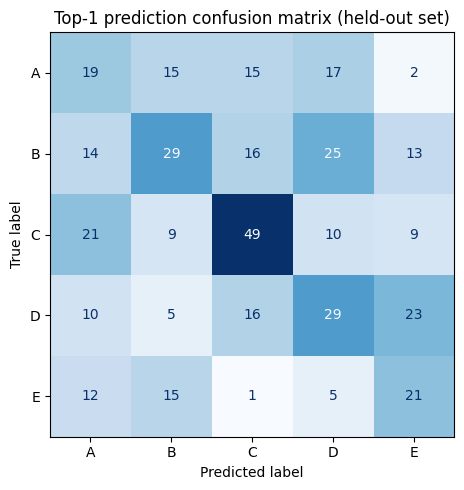

In [4]:
cm = confusion_matrix(top3_preds['answer'], top1_preds, labels=OPTION_COLS)
fig, ax = plt.subplots(figsize=(5.5, 5))
ConfusionMatrixDisplay(cm, display_labels=OPTION_COLS).plot(ax=ax, cmap='Blues', colorbar=False)
ax.set_title('Top-1 prediction confusion matrix (held-out set)')
plt.tight_layout()
plt.savefig('../reports/final_confusion_matrix.png', dpi=120)
plt.show()

## 3. Error analysis

### 3a. Does the model just learn "always guess a particular letter"?

The training labels' own class balance, and the model's top-1 prediction
distribution on held-out data, side by side.

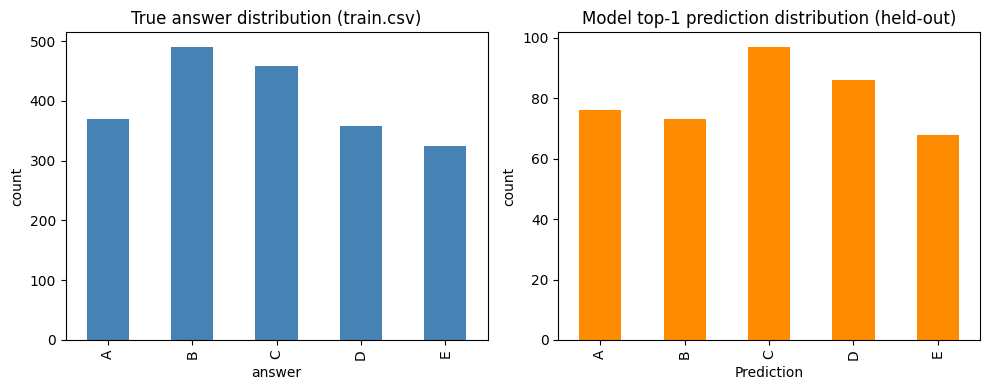

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
train['answer'].value_counts().reindex(OPTION_COLS).plot(kind='bar', ax=axes[0], color='steelblue')
axes[0].set_title('True answer distribution (train.csv)')
axes[0].set_ylabel('count')

top1_preds.value_counts().reindex(OPTION_COLS).plot(kind='bar', ax=axes[1], color='darkorange')
axes[1].set_title('Model top-1 prediction distribution (held-out)')
axes[1].set_ylabel('count')
plt.tight_layout()
plt.savefig('../reports/final_label_distribution.png', dpi=120)
plt.show()

### 3b. What does the model actually rely on?

Since the baseline is a linear `LogisticRegression` over 5 named features
(`src/utils.py`), its decision process is fully inspectable -- no black
box. But the raw coefficients alone are a trap: `word_overlap` and
`tfidf_cos_sim` are 0-1 ratios while `option_len`/`prompt_len` are raw
character counts in the hundreds, so a coefficient of `-1.08` on one and
`0.0014` on the other are **not directly comparable** -- a small
coefficient on a large-magnitude feature can matter just as much as a
large coefficient on a small one. Multiplying each coefficient by that
feature's standard deviation on this data (a standard fix -- it answers
"how much does a typical swing in this feature move the prediction")
gives an honest importance comparison instead.

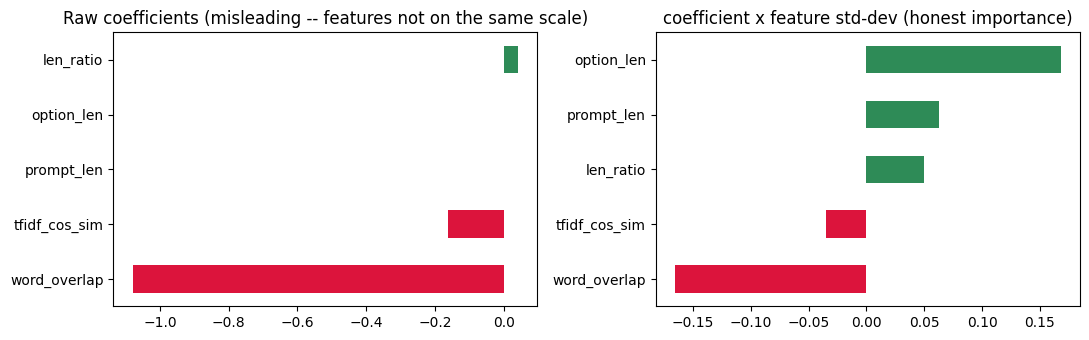

scale-adjusted importance, most -> least influential magnitude:
option_len       0.167963
word_overlap    -0.165334
prompt_len       0.062972
len_ratio        0.049467
tfidf_cos_sim   -0.034588
dtype: float64


In [6]:
raw_coefs = pd.Series(model.coef_[0], index=FEATURE_COLS)
feature_std = long_df[FEATURE_COLS].std()
scaled_importance = (raw_coefs * feature_std).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
raw_coefs.sort_values().plot(kind='barh', ax=axes[0], color=['crimson' if c < 0 else 'seagreen' for c in raw_coefs.sort_values()])
axes[0].set_title('Raw coefficients (misleading -- features not on the same scale)')

scaled_importance.plot(kind='barh', ax=axes[1], color=['crimson' if c < 0 else 'seagreen' for c in scaled_importance])
axes[1].set_title('coefficient x feature std-dev (honest importance)')
plt.tight_layout()
plt.savefig('../reports/final_model_coefficients.png', dpi=120)
plt.show()
print('scale-adjusted importance, most -> least influential magnitude:')
print(scaled_importance.reindex(scaled_importance.abs().sort_values(ascending=False).index))

### 3c. Concrete misclassified examples

Pull a few held-out questions where the top-3 prediction *missed* the
correct answer entirely (the actual failure mode mAP@3 penalizes).

In [7]:
misses = top3_preds[~top3_preds.apply(lambda r: r['answer'] in r['Prediction'].split(), axis=1)]
print(f'{len(misses)} / {len(top3_preds)} questions had no correct answer in the top 3')

for _, row in misses.head(3).iterrows():
    q = holdout[holdout['id'] == row['id']].iloc[0]
    print('-' * 80)
    print('PROMPT:', q['prompt'])
    print('TRUE ANSWER:', row['answer'], '->', q[row['answer']][:150])
    print('MODEL TOP-3:', row['Prediction'])

98 / 400 questions had no correct answer in the top 3
--------------------------------------------------------------------------------
PROMPT: Pick the best possible answer: What is a trophic level in an ecological pyramid? from the following choices.
TRUE ANSWER: C -> A group of organisms that acquire most of their energy from the level below them in the pyramid.
MODEL TOP-3: B E A
--------------------------------------------------------------------------------
PROMPT: Determine the correct option: What is the distinction between the coevolution of myrmecophytes and the mutualistic symbiosis of mycorrhiza? carefully.
TRUE ANSWER: A -> Myrmecophytes coevolve with ants, providing them with a home and sometimes food, while the ants defend the plant from herbivores and competing plants.
MODEL TOP-3: C D E
--------------------------------------------------------------------------------
PROMPT: Pick the best possible answer: What is the metallicity of Kapteyn's star estimated to be?
TRUE AN

### 3d. Length bias, quantified

Section 3b's scale-adjusted importance should show `option_len`/`len_ratio`
carrying real weight despite tiny raw coefficients -- meaning the model
partly rewards *longer* options. Check directly whether longer options
really are more likely to be correct in this data, or the model latched
onto noise.

In [8]:
holdout_c = holdout.copy()
for c in OPTION_COLS:
    holdout_c[c + '_len'] = holdout_c[c].str.len()

correct_len = holdout_c.apply(lambda r: r[r['answer'] + '_len'], axis=1)
avg_other_len = holdout_c.apply(lambda r: np.mean([r[c + '_len'] for c in OPTION_COLS if c != r['answer']]), axis=1)

gap_pct = (correct_len.mean() - avg_other_len.mean()) / avg_other_len.mean()
print(f'avg length of the CORRECT option:   {correct_len.mean():.1f} chars')
print(f'avg length of the OTHER 4 options:  {avg_other_len.mean():.1f} chars')
print(f'relative gap: {gap_pct:+.1%}')
print('-> not close: correct options really do run longer in this dataset, on average.')
print('   The model\'s length preference is exploiting a real (if modest and imperfect)')
print('   dataset regularity, not pure noise -- but it\'s also exactly the kind of')
print('   shortcut that would NOT generalize to a differently-written question set.')

avg length of the CORRECT option:   183.0 chars
avg length of the OTHER 4 options:  161.9 chars
relative gap: +13.0%
-> not close: correct options really do run longer in this dataset, on average.
   The model's length preference is exploiting a real (if modest and imperfect)
   dataset regularity, not pure noise -- but it's also exactly the kind of
   shortcut that would NOT generalize to a differently-written question set.


## 4. Refit on 100% of the labeled data for the final submission

The held-out 400 rows above were essential for an honest evaluation, but
holding them out of *training* forever would waste 20% of the labeled data
this project actually has. Standard practice once validation is done:
refit the exact same pipeline on the full training set before generating
the actual submission, so the deployed model has seen everything.

In [9]:
full_long = to_long_format(train, has_labels=True)
full_long, full_vectorizer = add_features(full_long, fit_vectorizer=True)

from sklearn.linear_model import LogisticRegression
final_model = LogisticRegression(max_iter=1000, class_weight='balanced')
final_model.fit(full_long[FEATURE_COLS], full_long['label'])

joblib.dump({'model': final_model, 'vectorizer': full_vectorizer}, '../models/baseline_final.joblib')
print('refit on all', len(train), 'training rows -> models/baseline_final.joblib')

refit on all 2000 training rows -> models/baseline_final.joblib


## 5. Generate the final Kaggle submission

In [10]:
test_long = to_long_format(test, has_labels=False)
test_long, _ = add_features(test_long, vectorizer=full_vectorizer, fit_vectorizer=False)
test_scores = final_model.predict_proba(test_long[FEATURE_COLS])[:, 1]

submission = top_k_predictions(test_long, test_scores, k=3)
submission = submission.rename(columns={'id': 'ID'})[['ID', 'Prediction']]

assert list(submission.columns) == list(sample_submission.columns), 'column mismatch vs sample_submission.csv'
assert len(submission) == len(sample_submission), 'row count mismatch vs sample_submission.csv'
assert submission['Prediction'].str.split().apply(len).eq(3).all(), 'every prediction must be exactly 3 options'

submission.to_csv('../reports/final_submission.csv', index=False)
print(f'wrote {len(submission)} predictions to reports/final_submission.csv')
submission.head()

wrote 500 predictions to reports/final_submission.csv


,ID,Prediction
0,1,D C B
1,2,E B D
2,3,E B C
3,4,D B E
4,5,E D A


**To actually submit**: upload `reports/final_submission.csv` on the
competition's Kaggle page (Submit Predictions), or, if the Kaggle CLI is
configured with your API credentials:

```bash
kaggle competitions submit -c <competition-slug> -f reports/final_submission.csv -m "Final submission: TF-IDF + LogisticRegression baseline"
```

## 6. Insights: the arc of this project

| Milestone | Approach | Headline finding |
|---|---|---|
| 1 | TF-IDF / Word2Vec cosine similarity | TF-IDF (0.296) actually *underperformed* random guessing (0.367) -- this dataset's distractors are built to share surface vocabulary with the prompt |
| 2 | Pretrained DistilBERT embeddings, zero-shot NLI | Semantic embeddings clearly beat lexical overlap (0.401 vs. 0.294); zero-shot NLI did best of the two (0.440) |
| 3 | RAG (Wikipedia retrieval + context) | Retrieved context *hurt* (0.440 -> 0.423) -- a retrieval-quality failure, not a reasoning one |
| 4 | LoRA fine-tuning (small-scale, 320 examples) | Directly optimizing for the task beat every zero-shot/RAG approach (0.5208) despite a tiny training set |
| 5 | Ensembling 5 models | The single best individual model (this baseline, 0.594) beat every ensemble (best: 0.5625) |
| Final | This baseline, refit on 100% of data | Chosen for submission on the strength of milestone 5's evidence, not assumption |

The throughline is less "which fancy technique wins" and more **"validate
before you trust a technique on this specific task/dataset"** -- three of
five milestones produced a result that would have been wrong to assume in
advance (TF-IDF losing to random, RAG hurting, ensembling losing to a
single model). Section 3 above shows the winning model isn't perfect
either: it's a small linear model over 5 hand-built features (including a
mild, only-partially-justified length preference), not a deep
understanding of the questions' content. The most honest summary of this
project's actual finding is that **a fully-trained simple model beat every
partially-trained or zero-shot sophisticated one** on this dataset and at
this scale -- which is itself a useful, generalizable lesson about where
to actually spend modeling effort, not a verdict on transformers/RAG/LoRA
being bad techniques in general.

For a properly resourced follow-up (GPU, full dataset, more epochs), the
LoRA fine-tuning direction (milestone 4) is the most promising place to
look for a genuine improvement over this baseline, since it's the only
approach that directly optimizes for this task's actual label
distribution rather than relying on generic pretrained knowledge or a
fixed linear feature set.